# Reproducing LMEnt Fig. 9 on **LMEnt-170M-6E**

*Entity mention forms and learning* — for each of the **14,267 PopQA facts**, compute
**% of training steps that introduce chunks explicitly mentioning both the subject
and the answer**, then group by fact frequency × correctness (paper §6.2 / Fig. 9).

### What this notebook does

| Step | Output |
|---|---|
| 1–5 | Clone LMEnt, pull the small index artifacts (~220 MB), load PopQA |
| 6–7 | `chunk_id → training step` (over `EPOCHS`) and `chunk_id → (part, token span)` |
| 8–9 | Stream the corpus metadata, classify every subject/answer mention as **explicit / alias / pronoun** |
| 10–11 | Per-fact `pct_steps_explicit` → `fig9_facts.csv` (all 14,267 rows) |
| 12 | 15-shot PopQA correctness at `step658032`, loaded from `data/artifacts/recall/` |
| 13 | Figure 9 |

### The data path (verified, not guessed)

The mention annotations are **not** in `dataset-cache`, and not in the `popqa-kas`
dataset. They are the **last-but-one column of `dataset-tokenized/part-N-00000.csv.gz`**
(8 files, ~32 GB). `setup.sh` merely gunzips those into the 212 GB
`dataset-metadata` — this notebook **streams them instead, so you never need 212 GB**.

Resolving a `chunk_id` to its mentions follows `NumpyKASVSLDataset.__getitem__` in
the LMEnt OLMo-core fork:

```
chunk_id ──(bucketed-doc-indices-part-N.npy, raw uint32 [start,end] pairs)──▶ token span
token span ──(nesting search over the CSV's per-document token spans)──▶ document row
document + span ──(offsets column: token→char)──▶ char range ──▶ entities in range
```

Checks that were run before writing this notebook, and that cell 7/10 re-assert:

* `Σ instances over the 8 parts = 10,491,928` = `max(chunk_id) + 1` in PopQA ✔
* instance token spans **nest inside** document token spans, all 8 parts, 0 mismatches ✔
* `batch_indices_epoch_{1..6}.npy` = 6 × 109,672 = 658,032 steps = the final
  checkpoint `step658032` ✔  (this run measures exposure over `EPOCHS` only)
* end-to-end spot check: *"Who is the father of Tyr?"* → chunk 742 → doc *Carolingian
  cross* → both `Q172713` (Tyr) and `Q43610` (Odin) present with hyperlink+EL evidence ✔

### Runtime / requirements

* **GPU runtime** (T4 is enough — the model is 170M).
* `MAX_STEPS_PER_FACT = N_EPOCHS * 1000` samples whole *steps*, so the `1–10` and
  `10–1K` buckets stay exact and the `1K+` estimate is unbiased (see cell 8). The
  cap scales with `len(EPOCHS)` — with the default single epoch it is the original
  1000, needing **508k** target chunks instead of 1.35M. Set `0` to remove
  sampling entirely.
* Wall clock: **~25 min** download (90 MB per epoch in `EPOCHS`, on top of the
  index artifacts) + **~30–50 min** streaming pass. No eval — correctness is read
  off the checkpoint sweep already in `data/artifacts/recall/`.
* Disk: peak ~9 GB (one part at a time, deleted after use).
* **Resumable** — every part writes its own parquet; re-running skips finished parts.

## 0 · Configuration

In [1]:
# ── model ────────────────────────────────────────────────────────────────────
MODEL_ID   = "dhgottesman/LMEnt-170M-6E"
CKPT       = "step658032"        # final checkpoint == 6 epochs (6 × 109,672)
TOTAL_EPOCHS = 6                 # epochs the model was actually trained for
EPOCHS     = [6]                 # which of them to measure exposure over.  OLMo-core
                                 # reshuffles every epoch, so each is its own schedule
                                 # and its own index file.  [6] = the epoch running up
                                 # to the checkpoint we score; list(range(1, 7)) = the
                                 # whole run.  See cell 6.
N_EPOCHS   = len(EPOCHS)
N_SHOTS    = 15                  # olmes PopQA default
MAX_GEN_TOKS = 15                # olmes PopQA default
EVAL_BATCH = 32                  # lower to 8/16 if you OOM

# ── mention extraction ───────────────────────────────────────────────────────
PARTS = list(range(8))           # [0] alone = quick smoke test (partial coverage)
MAX_STEPS_PER_FACT = N_EPOCHS * 1000  # cap on STEPS sampled per fact; 0 = no cap.
                                 # Each epoch contributes its own distinct steps, so
                                 # the cap scales with len(EPOCHS) to keep the 1-10
                                 # and 10-1K buckets EXACT.  With EPOCHS=[6] that is
                                 # the original 1000.
MIN_CAND_SCORE = 0.0             # see cell 9 — do NOT raise this to 0.3, it deletes every pronoun
KEEP_GZ = False                  # True = keep the 32 GB of .csv.gz on disk

# ── misc ─────────────────────────────────────────────────────────────────────
PROJECT_DIR = "/Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research"
WORK = f"{PROJECT_DIR}/work_170M_6E"
SEED = 0
DATASET_REPO = "dhgottesman/LMEnt-Dataset"

import os
os.makedirs(WORK, exist_ok=True)
print("work dir:", WORK)

work dir: /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E


## 1 · Environment

In [2]:
import subprocess, sys, shutil

gpu = shutil.which("nvidia-smi")
if gpu:
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total",
                          "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
else:
    print("!! No GPU detected — set Runtime ▸ Change runtime type ▸ GPU (cell 12 needs it)")

subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers>=4.44", "datasets", "huggingface_hub", "pyarrow",
                "pandas", "matplotlib", "accelerate"], check=True)

import numpy as np, pandas as pd
print("free disk:", round(shutil.disk_usage(WORK).free / 1e9, 1), "GB")

!! No GPU detected — set Runtime ▸ Change runtime type ▸ GPU (cell 12 needs it)
free disk: 33.8 GB


## 2 · Hugging Face authentication

Both repos are public but rate-limited; a token makes the 32 GB pull reliable.
In Colab, add your token to **🔑 Secrets** as `HF_TOKEN` and enable notebook access,
or paste it when prompted.

In [3]:
import os
tok = None
try:
    from google.colab import userdata
    tok = userdata.get("HF_TOKEN")
except Exception:
    pass
if not tok:
    from getpass import getpass
    tok = getpass("HF token (hf_...): ").strip()

os.environ["HF_TOKEN"] = tok
from huggingface_hub import login, whoami
login(token=tok, add_to_git_credential=False)
print("logged in as:", whoami()["name"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


logged in as: OmerOvadiaTAU


## 3 · Clone LMEnt and reuse its own code

We deliberately **do not re-implement** three things:

* `is_pronoun` / `normalize_span_text` — from `aggregate_entity_annotations/utils.py`.
  That module can't be imported (it opens an LMDB at a hard-coded `/home/morg/...`
  path at import time), so we lift the three pure functions out via `ast`.
* the `part-N ↔ hash` filename map — parsed out of `setup.sh`'s `ln -s` lines
  rather than hard-coded.
* the 15 PopQA few-shot exemplars — read from `olmes`' `FEWSHOT_SOURCES["popqa"]`.

In [4]:
import ast, os, re, subprocess, sys

LMENT = f"{WORK}/LMEnt"
if not os.path.isdir(LMENT):
    subprocess.run(["git", "clone", "--depth", "1", "-q",
                    "https://github.com/dhgottesman/LMEnt.git", LMENT], check=True)

# ---- (a) lift the pure helpers out of utils.py without importing it ---------
_src = open(f"{LMENT}/aggregate_entity_annotations/utils.py", encoding="utf-8").read()
_ns = {"re": re}
_want = {"is_pronoun", "strip_leading_article", "normalize_span_text"}
for _node in ast.parse(_src).body:
    if isinstance(_node, ast.FunctionDef) and _node.name in _want:
        exec(compile(ast.Module(body=[_node], type_ignores=[]), "<lment.utils>", "exec"), _ns)
is_pronoun          = _ns["is_pronoun"]
normalize_span_text = _ns["normalize_span_text"]
assert _want <= set(_ns), f"missing {_want - set(_ns)}"
assert is_pronoun("He") and is_pronoun("their") and not is_pronoun("Donald Trump")
assert normalize_span_text("the boy's") == "boy"

# ---- (b) part-N -> content hash, from setup.sh ------------------------------
HASHES = {"metadata": {}, "bucketed-doc-indices": {}}
for line in open(f"{LMENT}/setup.sh", encoding="utf-8"):
    line = line.strip()
    if not line.startswith("ln -s"):
        continue
    f = line.split()
    a, b = os.path.basename(f[2]), os.path.basename(f[3])
    m = re.match(r"(metadata|bucketed-doc-indices)-([0-9a-f]{64})\.npy$", a)
    n = re.match(r"(metadata|bucketed-doc-indices)-part-(\d+)-00000\.npy$", b)
    if m and n and m.group(1) == n.group(1):
        HASHES[m.group(1)][int(n.group(2))] = m.group(2)
assert all(len(v) == 8 for v in HASHES.values()), HASHES
print("part->hash map parsed from setup.sh:", {k: len(v) for k, v in HASHES.items()})

# ---- (c) the 15 fixed PopQA few-shot exemplars ------------------------------
# `git clone --depth 1` leaves submodules EMPTY, so olmes/ is normally not on disk.
# Use the checkout if it exists; otherwise fetch just that one file at the exact
# commit LMEnt pins — the gitlink sha is in the parent tree even in a shallow clone.
_FS_REL = "oe_eval/tasks/fewshot_sources.py"
_local = f"{LMENT}/olmes/{_FS_REL}"
if os.path.exists(_local):
    _fs = open(_local, encoding="utf-8").read()
    print("few-shot source: olmes submodule checkout")
else:
    _sha = subprocess.run(["git", "-C", LMENT, "ls-tree", "HEAD", "olmes"],
                          capture_output=True, text=True, check=True).stdout.split()[2]
    import urllib.request
    _fs = urllib.request.urlopen(
        f"https://raw.githubusercontent.com/dhgottesman/olmes/{_sha}/{_FS_REL}"
    ).read().decode("utf-8")
    print(f"few-shot source: fetched at LMEnt's pinned olmes commit {_sha[:10]}")

POPQA_FEWSHOT = None
import warnings
with warnings.catch_warnings():                 # their file has a stray \w escape
    warnings.simplefilter("ignore", SyntaxWarning)
    _fs_tree = ast.parse(_fs)
for _node in ast.walk(_fs_tree):
    if (isinstance(_node, ast.Assign) and len(_node.targets) == 1
            and isinstance(_node.targets[0], ast.Subscript)
            and isinstance(_node.targets[0].slice, ast.Constant)
            and _node.targets[0].slice.value == "popqa"):
        POPQA_FEWSHOT = ast.literal_eval(_node.value)
assert POPQA_FEWSHOT and len(POPQA_FEWSHOT) > N_SHOTS
print(f"few-shot pool: {len(POPQA_FEWSHOT)} exemplars (using first {N_SHOTS} after the leak filter)")

part->hash map parsed from setup.sh: {'metadata': 8, 'bucketed-doc-indices': 8}
few-shot source: fetched at LMEnt's pinned olmes commit 1f0568fb04
few-shot pool: 16 exemplars (using first 15 after the leak filter)


## 4 · Download the index artifacts (~310 MB for one epoch)

Only three things are needed, **not** the 506 MB dataloader instance indices and
**not** the 212 GB metadata:

| File | Size | Why |
|---|---|---|
| `batch_indices_epoch_{e}.npy`, `e in EPOCHS` | 90 MB each | step → chunk ids for that epoch (109,672 steps) |
| `bucketed-doc-indices-*.npy` ×8 | 81 MB | chunk_id → token span (raw `uint32` pairs) |
| `metadata-*.npy` ×8 | 52 MB | document counts per part (invariant check only) |

In [5]:
from huggingface_hub import hf_hub_download

def grab(rel):
    return hf_hub_download(DATASET_REPO, rel, repo_type="dataset",
                           local_dir=f"{WORK}/LMEnt-Dataset")

# One batch-index file per selected epoch (~90 MB each).  OLMo-core reshuffles with
# `get_rng(seed + epoch + seq_len)`, so every epoch is a different ordering:
# `batch_indices.npy` is byte-identical to `batch_indices_epoch_1.npy`, i.e. it is
# epoch 1 specifically -- NOT a schedule that covers the whole run.
BATCH_INDICES = {e: grab(f"dataset-cache/batch_indices_epoch_{e}.npy") for e in EPOCHS}
DOCIDX = {p: grab(f"dataset-cache/dataset-common/bucketed-doc-indices-{h}.npy")
          for p, h in sorted(HASHES["bucketed-doc-indices"].items())}
METAIDX = {p: grab(f"dataset-cache/dataset-metadata/metadata-{h}.npy")
           for p, h in sorted(HASHES["metadata"].items())}
print("downloaded:", len(BATCH_INDICES) + len(DOCIDX) + len(METAIDX), "files")

dataset-cache/batch_indices_epoch_6.npy:   0%|          | 0.00/90.0M [00:00<?, ?B/s]

dataset-cache/dataset-common/bucketed-do(…):   0%|          | 0.00/9.54M [00:00<?, ?B/s]

dataset-cache/dataset-common/bucketed-do(…):   0%|          | 0.00/12.2M [00:00<?, ?B/s]

dataset-cache/dataset-common/bucketed-do(…):   0%|          | 0.00/14.9M [00:00<?, ?B/s]

dataset-cache/dataset-common/bucketed-do(…):   0%|          | 0.00/9.12M [00:00<?, ?B/s]

...

dataset-cache/dataset-metadata/metadata-(…):   0%|          | 0.00/6.79M [00:00<?, ?B/s]

dataset-cache/dataset-metadata/metadata-(…):   0%|          | 0.00/6.79M [00:00<?, ?B/s]

dataset-cache/dataset-metadata/metadata-(…):   0%|          | 0.00/6.80M [00:00<?, ?B/s]

dataset-cache/dataset-metadata/metadata-(…):   0%|          | 0.00/6.80M [00:00<?, ?B/s]

downloaded: 17 files


## 5 · Load the 14,267 annotated PopQA facts

In [6]:
from datasets import load_dataset

qa = load_dataset("dhgottesman/popqa-kas")["train"]
facts = qa.to_pandas()
facts["shared_chunks"] = facts["shared_chunks"].apply(lambda a: np.asarray(a, dtype=np.int64))
print(f"{len(facts):,} facts | relations: {facts['prop'].nunique()}")
print(facts[["subj", "prop", "obj", "num_shared_chunks"]].head(3).to_string(index=False))
print("\nnum_shared_chunks: median %.0f  mean %.1f  max %d  |  %d facts have 0"
      % (facts.num_shared_chunks.median(), facts.num_shared_chunks.mean(),
         facts.num_shared_chunks.max(), (facts.num_shared_chunks == 0).sum()))

14,267 facts | relations: 16
         subj       prop        obj  num_shared_chunks
George Rankin occupation politician                  0
   John Mayne occupation journalist                  0
Henry Feilden occupation politician                  0

num_shared_chunks: median 3  mean 176.4  max 101081  |  2450 facts have 0


## 6 · `chunk_id → training step`

`LMEnt-170M-6E` is a **six-epoch** model, and OLMo-core reshuffles every epoch
(`data_loader.py`: `get_rng(seed + epoch + seq_len)`), so there is no single ordering
covering the run. `batch_indices.npy` is byte-identical to
`batch_indices_epoch_1.npy` — it is epoch **1** specifically, which is the wrong
epoch to pair with correctness at `step658032`. All six per-epoch files are
published, so picking the right one needs no seed hunt or dataloader replay.

`EPOCHS = [6]` (cell 0) measures exposure over the **final epoch**, steps
548,360–658,032 — the run-up to the checkpoint we score. Within an epoch every chunk
appears **exactly once**, so a chunk maps to one step per selected epoch and the map
is `steps_of_chunk[chunk, i]` for `i` indexing `EPOCHS`. Global steps are

```
global_step = (epoch - 1) * 109,672 + local_step
```

so they stay comparable across any choice of `EPOCHS`.

**Why one epoch is enough.** Every fact sees *all* of its chunks in *every* epoch, so
`pct_steps_explicit` — a ratio — is close to epoch-invariant; a single epoch measures
it at 1/6 the download, memory and parsing cost, and keeps the step cap at its
original 1000. Set `EPOCHS = list(range(1, 7))` to pool all six (~252 MB map, and a
6× larger cap, which retains substantially more target chunks in cell 8).


In [7]:
STEPS_PER_EPOCH = 109_672
N_CHUNKS = 10_491_928                      # re-asserted in cell 7 from the index files

# chunk -> the GLOBAL step it was served at, once per selected epoch.  A chunk appears
# exactly once per epoch but at a different step each time, so this is
# (N_CHUNKS, len(EPOCHS)) -- column i is EPOCHS[i].  ~42 MB per epoch as int32.
steps_of_chunk = np.full((N_CHUNKS, N_EPOCHS), -1, dtype=np.int32)
for col, epoch in enumerate(EPOCHS):
    bi = np.load(BATCH_INDICES[epoch], allow_pickle=True)
    assert len(bi) == STEPS_PER_EPOCH, (epoch, len(bi))
    base = (epoch - 1) * STEPS_PER_EPOCH   # global = (epoch-1)*109672 + local
    for s, ids in enumerate(bi):
        steps_of_chunk[np.asarray(ids, dtype=np.int64), col] = base + s
    if col == 0:
        bsz = (min(len(x) for x in bi[:5000]), max(len(x) for x in bi[:5000]))
    del bi
    print(f"  epoch {epoch} mapped -> global steps "
          f"{base:,}..{base + STEPS_PER_EPOCH - 1:,}", flush=True)

N_STEPS_TRAINED = TOTAL_EPOCHS * STEPS_PER_EPOCH        # the model's full schedule
N_STEPS = N_EPOCHS * STEPS_PER_EPOCH                    # what this run measures over
assert CKPT == f"step{N_STEPS_TRAINED}", \
    f"{CKPT} != step{N_STEPS_TRAINED} — is this really a {TOTAL_EPOCHS}-epoch model?"
assert set(EPOCHS) <= set(range(1, TOTAL_EPOCHS + 1)), EPOCHS

sched = steps_of_chunk >= 0
seen = int(sched.any(axis=1).sum())
print(f"measuring {N_STEPS:,} steps (epochs {EPOCHS}) of the model's "
      f"{N_STEPS_TRAINED:,} | {seen:,} chunks scheduled "
      f"({100*seen/N_CHUNKS:.2f}% of the corpus)")
print(f"batch size varies {bsz[0]}–{bsz[1]} (VSL grow-p2)")

# Every scheduled chunk should be scheduled in EVERY selected epoch — that invariant is
# what makes the step counts comparable, so report it rather than assume it.
per_chunk = sched.sum(axis=1)
mixed = int(((per_chunk > 0) & (per_chunk < N_EPOCHS)).sum())
print(f"chunks scheduled in all {N_EPOCHS} selected epoch(s): "
      f"{int((per_chunk == N_EPOCHS).sum()):,}"
      + (f"   !! {mixed:,} scheduled in only some — the ratio in cell 11 is no longer "
         f"epoch-balanced for those" if mixed else "   ✔"))
del sched, per_chunk

  epoch 6 mapped -> global steps 548,360..658,031
measuring 109,672 steps (epochs [6]) of the model's 658,032 | 10,478,080 chunks scheduled (99.87% of the corpus)
batch size varies 16–512 (VSL grow-p2)
chunks scheduled in all 1 selected epoch(s): 10,478,080   ✔


## 7 · `chunk_id → (part, token span)`

`bucketed-doc-indices-part-N.npy` is a **headerless raw `uint32` array** of
`[start, end]` token pairs — one pair per instance — read by OLMo-core as
`load_array_slice_into_tensor(path, i*2, i*2+2, uint32)`. `np.load` fails on it;
`np.memmap` is correct. `chunk_id` is the **global** instance index with parts
concatenated in order 0…7.

In [8]:
spans, counts = {}, []
for p in range(8):
    a = np.memmap(DOCIDX[p], dtype=np.uint32, mode="r")
    assert len(a) % 2 == 0
    spans[p] = a
    counts.append(len(a) // 2)

part_offset = np.cumsum([0] + counts)              # global id of each part's first instance
total = int(part_offset[-1])
assert total == N_CHUNKS, f"{total} != {N_CHUNKS}"
assert facts.shared_chunks.map(lambda a: a.max() if len(a) else -1).max() < N_CHUNKS

DOCS_PER_PART = {p: len(np.load(METAIDX[p])) for p in range(8)}
print(f"instances/part: {counts}  ->  total {total:,} == max(chunk_id)+1  ✔")
print(f"documents/part: {list(DOCS_PER_PART.values())}  ->  total {sum(DOCS_PER_PART.values()):,}")

def locate(cid):
    """chunk_id -> (part, tok_start, tok_end)"""
    p = int(np.searchsorted(part_offset, cid, "right") - 1)
    i = (cid - int(part_offset[p])) * 2
    return p, int(spans[p][i]), int(spans[p][i + 1])

print("example:", 742, "->", locate(742))

instances/part: [1192979, 1521964, 1863222, 1140030, 1214198, 1188175, 1232275, 1139085]  ->  total 10,491,928 == max(chunk_id)+1  ✔
documents/part: [849203, 848336, 845782, 849548, 848907, 848837, 849513, 849685]  ->  total 6,789,811
example: 742 -> (0, 212373, 212884)


## 8 · Choose the target chunks

Fig. 9 only looks at chunks where the **(Subject, Answer) pair co-occurs** —
`shared_chunks`. Parsing all 1,345,706 of them (12.8 % of the corpus) is the
expensive path, so we subsample — but **we sample steps, not chunks**, and then take
*every* chunk of each sampled step.

That distinction matters. The metric asks whether a step introduces **any** chunk
with both entities explicit, so dropping some of a step's chunks can only ever turn
an explicit step into a non-explicit one — subsampling chunks **biases the metric
downward**. Sampling whole steps observes each sampled step completely, so the
estimate is unbiased. Measured multiplicity (a fact's chunks landing in the same
step) shows where that would have bitten:

| bucket | facts | chunks per distinct step |
|---|---|---|
| 1–10 | 8,356 | 1.000 |
| 10–1K | 3,150 | 1.002 |
| 1K–10K | 259 | 1.024 |
| **10K+** | **52** | **1.213** |

— i.e. precisely the `1K+` bucket where Fig. 9's effect lives.

`MAX_STEPS_PER_FACT = N_EPOCHS * 1000` lines up with the paper's bucket edge: the
`10–1K` bucket can't exceed 1000 co-occurrences, and one epoch turns each into at
most one step, so **both lower buckets come out exact** and only the 311 facts in
`1K+` are sampled at all. With the default `EPOCHS = [6]` the cap is 1000 and the
cost is the 508,361 chunks quoted above.

The measured multiplicities in the table are per epoch, so they hold for any single
epoch. Pooling several multiplies a fact's distinct steps and its counted chunks by
roughly the same factor, leaving chunks-per-step near-unchanged — but a capped fact
then keeps every chunk landing in a chosen step *in any* epoch, so the target-chunk
count (printed below) grows faster than the cap does. **Check that number before
running cell 9**, whose runtime scales with it.

Chunks the selected epoch never scheduled (`step == -1`, ~0.13 %) are dropped here:
the model never saw them, so they cannot belong to any step.

In [9]:
rng = np.random.default_rng(SEED)

per_fact, per_steps, n_sampled = [], [], 0
for arr in facts.shared_chunks:
    a = arr.astype(np.int64)
    if len(a) == 0:
        per_fact.append(a); per_steps.append(np.empty(0, dtype=np.int32)); continue
    st = steps_of_chunk[a]                    # (len(a), N_EPOCHS) global steps
    keep = (st >= 0).any(axis=1)              # never scheduled -> can't be in any step
    a, st = a[keep], st[keep]
    steps = np.unique(st[st >= 0])            # every epoch's steps, pooled
    if MAX_STEPS_PER_FACT and len(steps) > MAX_STEPS_PER_FACT:
        steps = np.sort(rng.choice(steps, MAX_STEPS_PER_FACT, replace=False))
        a = a[np.isin(st, steps).any(axis=1)]  # ALL chunks of each chosen step
        n_sampled += 1
    per_fact.append(np.sort(a))
    per_steps.append(steps.astype(np.int32))
facts["chunks_used"] = per_fact
# The exact step set cell 11 is allowed to count.  It cannot be re-derived from
# chunks_used: a chunk kept because ONE of its six epochs landed in a chosen step
# still carries the five steps that were not chosen.
facts["steps_used"] = per_steps

targets = np.unique(np.concatenate([a for a in per_fact if len(a)])).astype(np.int64)
print(f"target chunks: {len(targets):,}  ({100*len(targets)/N_CHUNKS:.2f}% of corpus)")
print(f"facts subsampled: {n_sampled:,} / {len(facts):,} "
      f"(the rest are exact) | cap = {MAX_STEPS_PER_FACT or 'none'} steps "
      f"of {N_STEPS:,} across {N_EPOCHS} epochs")

# QIDs we care about, plus canonical surface forms per QID
QIDS = sorted(set(facts.s_uri) | set(facts.o_uri))
QCODE = {q: i for i, q in enumerate(QIDS)}

def _norm(s):
    s = re.sub(r"\s*\([^)]*\)\s*$", "", str(s))          # drop wiki disambiguation
    s = normalize_span_text(s)                            # LMEnt: article + possessive
    return re.sub(r"\s+", " ", s).strip().strip(".,;:'\"").lower()

CANON = {}
for col_q, col_n, col_t in (("s_uri", "subj", "s_wiki_title"), ("o_uri", "obj", "o_wiki_title")):
    for q, n, t in zip(facts[col_q], facts[col_n], facts[col_t]):
        CANON.setdefault(q, set()).update({_norm(n), _norm(t)})
print(f"{len(QIDS):,} distinct entities; canonical forms e.g. Q43610 -> {CANON.get('Q43610')}")

# per-part target index, sorted by token start
by_part = {}
for p in PARTS:
    ids = targets[(targets >= part_offset[p]) & (targets < part_offset[p + 1])]
    loc = (ids - part_offset[p]) * 2
    ts, te = spans[p][loc].astype(np.int64), spans[p][loc + 1].astype(np.int64)
    o = np.argsort(ts, kind="stable")
    by_part[p] = (ts[o], te[o], ids[o])
    print(f"  part-{p}: {len(ids):,} target chunks")

target chunks: 508,240  (4.84% of corpus)
facts subsampled: 311 / 14,267 (the rest are exact) | cap = 1000 steps of 109,672 across 1 epochs
19,384 distinct entities; canonical forms e.g. Q43610 -> {'odin'}
  part-0: 47,346 target chunks
  part-1: 79,297 target chunks
  part-2: 136,832 target chunks
  part-3: 44,617 target chunks
  part-4: 47,540 target chunks
  part-5: 52,238 target chunks
  part-6: 55,585 target chunks
  part-7: 44,785 target chunks


## 9 · Extract mention forms  ⏳ *the long cell*

For every target chunk we replicate `NumpyKASVSLDataset.__getitem__`:

```python
cs, ce = tok_start - doc_start, tok_end - doc_start
c0 = offsets[cs][0]
c1 = offsets[min(ce, len(offsets)) - 1][1]      # len(offsets) is 1 short of the token count
keep entities with  c0 <= char_start and c1 >= char_end
```

then label each mention by its **top-scoring candidate**:

| form | rule |
|---|---|
| **pronoun** (0) | `is_pronoun(text_mention)` — LMEnt's own regex |
| **explicit** (2) | normalised `text_mention` == a canonical name (`subj`/`s_wiki_title`, or the candidate's own `name`) |
| **alias** (1) | linked to the QID, but neither of the above |

> ### ⚠️ Why `MIN_CAND_SCORE = 0.0` and not `0.3`
>
> `aggregate_mentions` weights evidence `hyperlinks=4, entity_linking=3, coref=2,
> coref_cluster=1` over a total of 10 — so a mention supported **only** by
> coreference can never exceed `(2+1)/10 = 0.30`. Measured over 2,512 documents of
> part-0:
>
> | evidence | n | median score | % below 0.3 |
> |---|---|---|---|
> | coref only, **pronoun** | 30,222 | 0.07 | **100 %** |
> | coref only, nominal | 68,243 | 0.03 | 96 % |
> | hyperlink/EL only | 48,581 | 0.40 | 37 % |
>
> Filtering at `0.3` therefore deletes **every pronoun** — the exact category Fig. 9
> is about — and a third of the explicit mentions too. The candidates published in
> this corpus already passed the pipeline's own `0.3` gate at annotation time
> (`run_aggregate_entity_annotations.py:49`), so no further threshold belongs here.
> Ambiguity is handled instead by **rank**: a mention may only be called *explicit*
> when the matching candidate is its **top-scoring** one, so a "Washington" span
> can't be claimed as an explicit mention of whichever Washington we happen to be
> asking about. Lower-ranked matches are demoted to *alias*.
>
> Rank matters for the diagnostic too: measured on the same sample, top-1 alone finds
> only **34 %** (603/1,761) of the pronoun mentions that reference a tracked entity —
> pronouns carry 2–8 competing coref candidates — versus 72 % for nominal spans. The
> metric itself is unaffected (its numerator needs *explicit* mentions only), but the
> printed explicit/alias/pronoun mix would be badly skewed by a top-1-only rule.

**Speed trick:** each CSV line is scanned as *bytes* for just the first two
comma-separated ints (the document's token span). Only the ~3 % of documents that
actually contain a target chunk get fully parsed — so the 212 GB of text costs a
`zlib` pass plus two `bytes.find` calls per line, not 6.8 M JSON parses.

Each part writes `mentions_part{N}.parquet` and is then deleted; **re-running skips
completed parts**.

In [11]:
import csv, gzip, io, json, time
from ast import literal_eval
from huggingface_hub import hf_hub_download

csv.field_size_limit(min(sys.maxsize, (1 << 31) - 1))
HEAD = ["start", "end", "id", "src", "loc", "title", "entities", "offsets"]
PRONOUN, ALIAS, EXPLICIT = 0, 1, 2

def classify(text, cand_name, qid):
    if is_pronoun(text):
        return PRONOUN
    n = _norm(text)
    if n and (n in CANON.get(qid, ()) or n == _norm(cand_name or "")):
        return EXPLICIT
    return ALIAS

def process_part(p):
    out = f"{WORK}/mentions_part{p}.parquet"
    if os.path.exists(out):
        print(f"part-{p}: already done -> {out}")
        return out

    tstart, tend, tcid = by_part[p]
    n = len(tstart)
    if n == 0:
        pd.DataFrame({"chunk_id": [], "qid": [], "form": []}).to_parquet(out)
        return out

    print(f"part-{p}: downloading .csv.gz ...", flush=True)
    gz = hf_hub_download(DATASET_REPO, f"dataset-tokenized/part-{p}-00000.csv.gz",
                         repo_type="dataset", local_dir=f"{WORK}/tok")

    rows_cid, rows_qid, rows_form = [], [], []
    ptr = docs = parsed = 0
    t0 = time.time()
    with gzip.open(gz, "rb") as fh:
        for line in fh:
            i1 = line.find(b",")
            i2 = line.find(b",", i1 + 1)
            ds, de = int(line[:i1]), int(line[i1 + 1:i2])
            docs += 1

            while ptr < n and tstart[ptr] < ds:      # targets in already-passed docs
                ptr += 1
            j = ptr
            while j < n and tstart[j] < de:
                j += 1
            if j == ptr:
                continue                              # no target chunk in this document

            row = next(csv.reader([line.decode("utf-8", "replace")]))
            if len(row) < 8:
                ptr = j
                continue
            rec = dict(zip(HEAD, row))
            ents = json.loads(rec["entities"])
            offs = np.array(re.findall(r"\d+", rec["offsets"]), dtype=np.int64).reshape(-1, 2)
            parsed += 1

            # Keep every candidate that points at an entity we track, but only the
            # mention's TOP candidate may be called `explicit` (see note above).
            hits = []
            for e in ents:
                cands = e["candidates"]
                if not cands:
                    continue
                top = max(cands, key=lambda c: float(c.get("aggregated_score", 0.0)))
                for c in cands:
                    q = c["qid"]
                    if q not in QCODE or float(c.get("aggregated_score", 0.0)) < MIN_CAND_SCORE:
                        continue
                    hits.append((e["char_start"], e["char_end"], e["text_mention"],
                                 c.get("name"), q, c is top))
            if hits:
                for k in range(ptr, j):
                    cs, ce = int(tstart[k]) - ds, int(tend[k]) - ds
                    if cs < 0 or cs >= len(offs):
                        continue
                    c0 = int(offs[cs][0]); c1 = int(offs[min(ce, len(offs)) - 1][1])
                    cid = int(tcid[k])
                    for hs, he, txt, cname, q, is_top in hits:
                        if c0 <= hs and c1 >= he:
                            f = classify(txt, cname, q)
                            if f == EXPLICIT and not is_top:
                                f = ALIAS          # ambiguous: don't claim explicitness
                            rows_cid.append(cid); rows_qid.append(QCODE[q])
                            rows_form.append(f)
            ptr = j
            if ptr >= n:
                break

    raw = np.bincount(np.array(rows_form, dtype=np.int64), minlength=3)
    json.dump({"raw_form_counts": raw.tolist(), "docs_scanned": docs,
               "docs_expected": DOCS_PER_PART[p], "docs_parsed": parsed},
              open(f"{WORK}/forms_part{p}.json", "w"))

    # one row per (chunk, entity), keeping the MOST EXPLICIT form seen in that chunk
    df = (pd.DataFrame({"chunk_id": np.array(rows_cid, dtype=np.int64),
                        "qid": np.array(rows_qid, dtype=np.int32),
                        "form": np.array(rows_form, dtype=np.int8)})
          .groupby(["chunk_id", "qid"], as_index=False)["form"].max())
    df.to_parquet(out, index=False)

    if not KEEP_GZ:
        os.remove(gz)
    if docs != DOCS_PER_PART[p]:
        print(f"part-{p}: WARNING scanned {docs:,} docs but the index expects "
              f"{DOCS_PER_PART[p]:,} — truncated stream?")
    print(f"part-{p}: {docs:,} docs scanned, {parsed:,} fully parsed, "
          f"{len(df):,} (chunk,entity) rows, {time.time()-t0:.0f}s", flush=True)
    return out

paths = [process_part(p) for p in PARTS]
mentions = pd.concat([pd.read_parquet(f) for f in paths], ignore_index=True)

RAW_FORMS = np.zeros(3, dtype=np.int64)
for p in PARTS:
    RAW_FORMS += np.array(json.load(open(f"{WORK}/forms_part{p}.json"))["raw_form_counts"])

print(f"\nTOTAL {len(mentions):,} (chunk, entity) rows over parts {PARTS}")
print(f"raw mentions: explicit {RAW_FORMS[2]:,}  alias {RAW_FORMS[1]:,}  "
      f"pronoun {RAW_FORMS[0]:,}")

part-0: already done -> /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/mentions_part0.parquet
part-1: already done -> /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/mentions_part1.parquet
part-2: already done -> /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/mentions_part2.parquet
part-3: already done -> /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/mentions_part3.parquet
part-4: downloading .csv.gz ...


dataset-tokenized/part-4-00000.csv.gz:   0%|          | 0.00/2.96G [00:00<?, ?B/s]

part-4: WARNING scanned 848,877 docs but the index expects 848,907 — truncated stream?
part-4: 848,877 docs scanned, 42,977 fully parsed, 295,268 (chunk,entity) rows, 141s
part-5: downloading .csv.gz ...


dataset-tokenized/part-5-00000.csv.gz:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

part-5: WARNING scanned 848,821 docs but the index expects 848,837 — truncated stream?
part-5: 848,821 docs scanned, 46,911 fully parsed, 364,741 (chunk,entity) rows, 164s
part-6: downloading .csv.gz ...


dataset-tokenized/part-6-00000.csv.gz:   0%|          | 0.00/3.30G [00:00<?, ?B/s]

part-6: WARNING scanned 849,508 docs but the index expects 849,513 — truncated stream?
part-6: 849,508 docs scanned, 49,691 fully parsed, 387,049 (chunk,entity) rows, 159s
part-7: downloading .csv.gz ...


dataset-tokenized/part-7-00000.csv.gz:   0%|          | 0.00/3.19G [00:00<?, ?B/s]

part-7: WARNING scanned 849,667 docs but the index expects 849,685 — truncated stream?
part-7: 849,667 docs scanned, 40,998 fully parsed, 287,068 (chunk,entity) rows, 164s

TOTAL 3,842,962 (chunk, entity) rows over parts [0, 1, 2, 3, 4, 5, 6, 7]
raw mentions: explicit 5,951,404  alias 11,773,182  pronoun 2,728,404


## 10 · Validation

Independent of the aggregation: re-resolve a random high-frequency fact from scratch
and confirm the subject and answer really are in the chunk we claim.

In [12]:
expl_by_qid = (mentions[mentions.form == EXPLICIT]
               .groupby("qid")["chunk_id"].apply(lambda s: set(s.tolist())).to_dict())
any_by_qid  = mentions.groupby("qid")["chunk_id"].apply(lambda s: set(s.tolist())).to_dict()

def in_scanned(a):
    """Keep only chunks living in a part we actually streamed (PARTS may be sparse)."""
    if len(a) == 0:
        return a
    m = np.zeros(len(a), dtype=bool)
    for p in PARTS:
        m |= (a >= part_offset[p]) & (a < part_offset[p + 1])
    return a[m]

# Pick the fact with the most both-explicit chunks, so this stays informative even
# on a partial `PARTS` run (a random fact would usually have nothing scanned yet).
best = None
for f in facts.itertuples():
    ch = in_scanned(f.chunks_used)
    if len(ch) == 0:
        continue
    es = expl_by_qid.get(QCODE[f.s_uri], ())
    eo = expl_by_qid.get(QCODE[f.o_uri], ())
    n = sum(1 for c in ch if c in es and c in eo)
    if best is None or n > best[0]:
        best = (n, f, ch)

nboth, cand, ch = best
sq, oq = QCODE[cand.s_uri], QCODE[cand.o_uri]
both = [c for c in ch if c in expl_by_qid.get(sq, ()) and c in expl_by_qid.get(oq, ())]

print(f"FACT  {cand.question!r}")
print(f"  subj={cand.subj!r} ({cand.s_uri})   answer={cand.obj!r} ({cand.o_uri})")
print(f"  num_shared_chunks={cand.num_shared_chunks}  scanned={len(ch)}")
print(f"  chunks with BOTH explicit: {len(both)}")
print(f"  subject mentioned at all in {sum(c in any_by_qid.get(sq, ()) for c in ch)} chunks; "
      f"answer in {sum(c in any_by_qid.get(oq, ()) for c in ch)}")
if both:
    p_, s_, e_ = locate(both[0])
    print(f"  -> e.g. chunk {both[0]} = part-{p_}, tokens [{s_},{e_}), "
          f"steps {steps_of_chunk[both[0]].tolist()} (one per epoch)")
else:
    print("  !! nothing both-explicit anywhere — stop and debug before trusting cell 11")

# form mix across the whole corpus, per role
sub_q, ans_q = set(QCODE[q] for q in facts.s_uri), set(QCODE[q] for q in facts.o_uri)
print("\nmention-form mix (per (chunk, entity), most explicit form kept):")
for label, qs in (("subjects", sub_q), ("answers", ans_q)):
    m = mentions[mentions.qid.isin(qs)]
    d = m.form.value_counts(normalize=True).reindex([2, 1, 0]).fillna(0) * 100
    print(f"  {label:9s}: explicit {d[2]:5.1f}%  alias {d[1]:5.1f}%  pronoun {d[0]:5.1f}%"
          f"   (n={len(m):,})")

# Raw mention-level mix. NOTE the table above is per (chunk, entity) AFTER taking
# the most explicit form, so a chunk naming the entity once and pronouning it twice
# counts as `explicit` — pronoun shares there are legitimately near zero. Only the
# raw counts can tell you whether the implicit category is being captured at all.
raw_pct = 100 * RAW_FORMS / max(1, RAW_FORMS.sum())
print(f"\nraw mention-level: explicit {raw_pct[2]:.1f}%  alias {raw_pct[1]:.1f}%  "
      f"pronoun {raw_pct[0]:.1f}%  (n={RAW_FORMS.sum():,})")
if RAW_FORMS[0] == 0 and RAW_FORMS.sum() > 10_000:
    print("  !! no pronouns at all in a large sample — MIN_CAND_SCORE is probably "
          "filtering coref evidence (see the note above)")

FACT  'What is London the capital of?'
  subj='London' (Q84)   answer='England' (Q21)
  num_shared_chunks=73367  scanned=1408
  chunks with BOTH explicit: 1349
  subject mentioned at all in 1408 chunks; answer in 1408
  -> e.g. chunk 2320 = part-0, tokens [703159,703223), steps [603905] (one per epoch)

mention-form mix (per (chunk, entity), most explicit form kept):
  subjects : explicit  79.8%  alias  19.8%  pronoun   0.3%   (n=2,569,456)
  answers  : explicit  79.5%  alias  20.2%  pronoun   0.3%   (n=2,978,354)

raw mention-level: explicit 29.1%  alias 57.6%  pronoun 13.3%  (n=20,452,990)


## 11 · The Fig. 9 metric, per fact

> *"For each (Subject, Answer) entity pair, we compute the proportion of training
> steps that introduce chunks which explicitly mention both entities."*

```
pct_steps_explicit = 100 * |steps introducing ≥1 co-occurrence chunk with BOTH explicit|
                         / |steps introducing ≥1 co-occurrence chunk|
```

Steps are counted over the epochs in `EPOCHS` (default: epoch 6 alone, global steps
548,360–658,032), so a chunk contributes one step per selected epoch. Only the steps
in `steps_used` are counted — for the 311 capped facts that is the sampled subset,
for everyone else it is every step they have.

`n_chunks_scanned` only counts chunks in the parts you actually ran, so a partial
`PARTS` run stays honest instead of silently reporting zeros.

In [13]:
def _steps(chunks, allowed):
    """Distinct global steps these chunks were served at, restricted to the step set
    cell 8 sampled.  A kept chunk still carries the epochs whose steps were NOT
    chosen, so the restriction is what keeps the capped facts unbiased."""
    if len(chunks) == 0:
        return set()
    s = steps_of_chunk[chunks].ravel()
    s = s[s >= 0]
    return set(s[np.isin(s, allowed)].tolist())

rec = []
for f in facts.itertuples():
    ch = in_scanned(f.chunks_used)
    if len(ch) == 0:
        rec.append((0, 0, 0, np.nan)); continue
    allowed = f.steps_used
    sq, oq = QCODE[f.s_uri], QCODE[f.o_uri]
    es, eo = expl_by_qid.get(sq, ()), expl_by_qid.get(oq, ())
    both = np.array([c for c in ch if c in es and c in eo], dtype=np.int64)
    nd, nn = len(_steps(ch, allowed)), len(_steps(both, allowed))
    rec.append((len(ch), nd, nn, 100.0 * nn / nd if nd else np.nan))

out = facts[["id", "subj", "prop", "obj", "s_uri", "o_uri", "num_shared_chunks"]].copy()
out[["n_chunks_scanned", "n_steps_total", "n_steps_explicit", "pct_steps_explicit"]] = \
    pd.DataFrame(rec, index=out.index)

cov = out.n_chunks_scanned.sum() / max(1, sum(len(a) for a in facts.chunks_used))
print(f"coverage of sampled chunks by scanned parts: {100*cov:.1f}%")
print(f"facts with a defined metric: {out.pct_steps_explicit.notna().sum():,} / {len(out):,}")
print(out.pct_steps_explicit.describe().round(2).to_string())
out.to_csv(f"{WORK}/fig9_facts.csv", index=False)
print("\nwrote", f"{WORK}/fig9_facts.csv")

coverage of sampled chunks by scanned parts: 100.0%
facts with a defined metric: 11,817 / 14,267
count    11817.00
mean        75.01
std         30.77
min          0.00
25%         60.00
50%         87.00
75%        100.00
max        100.00

wrote /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/fig9_facts.csv


## 12 · Correctness at `step658032` — read from the checkpoint sweep

Cells 12a/12b below are the original in-notebook `olmes` eval, **left commented
out**: `feature_extraction/eval_checkpoints.py` already swept every checkpoint of
this model, so re-running 14,248 greedy decodes here would only reproduce work that
is sitting in `data/artifacts/recall/170M_6E_15shot_trajectory/`.

Cell 12c loads the final-checkpoint parquet and joins `correct` onto `out` by `id`.

**The prompting protocol is not the commented-out one.** That sweep uses the cloze
form from `src/lment_popqa.py` (`"The occupation of George Rankin is"`) with
demonstrations chosen by `src/fewshot.py` in `drop-same-prop` mode, where the
commented-out cells use `olmes`' `"Q: … A:"` with the verbatim
`FEWSHOT_SOURCES["popqa"]` block and its `is_safe` leak filter. Same model, same
checkpoint, both 15-shot and both substring-scored, so the correct/incorrect split
is valid either way — but it is not the `olmes`-faithful one, and the sweep's
protocol is the less leaky of the two.

The parquet covers 14,248 of the 14,267 facts; the 19 missing ones are the few-shot
pool subjects that `fewshot.drop_subjects` holds out, and the join drops them.

In [14]:
# import torch
# from transformers import AutoModelForCausalLM, AutoTokenizer

# tokz = AutoTokenizer.from_pretrained(MODEL_ID, subfolder=CKPT, use_fast=True)
# model = AutoModelForCausalLM.from_pretrained(
#     MODEL_ID, subfolder=CKPT,
#     torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
# ).eval()
# if torch.cuda.is_available():
#     model = model.cuda()
# if tokz.pad_token_id is None:
#     tokz.pad_token = tokz.eos_token
# tokz.padding_side = "left"
# print(f"{MODEL_ID}/{CKPT}: {sum(p.numel() for p in model.parameters())/1e6:.0f}M params")

# def doc_to_text(q):   return "Q: " + q + " A:"
# def doc_to_target(o): return " " + o

# def build_prompt(question, answers):
#     labels = [a.lower() for a in answers] + [a.capitalize() for a in answers]
#     shots = []
#     for ex in POPQA_FEWSHOT:
#         t, g = doc_to_text(ex["question"]), doc_to_target(ex["obj"])
#         if all(a not in t and a not in g for a in labels):     # olmes is_safe
#             shots.append(t + g)
#         if len(shots) == N_SHOTS:
#             break
#     return "\n\n".join(shots) + "\n\n" + doc_to_text(question), len(shots)

# def is_correct(pred, answers):
#     for lab in [a for a in answers if len(a) > 3]:
#         if lab in pred or lab.lower() in pred or lab.capitalize() in pred:
#             return True
#     return False

# prompts, nshots = zip(*[build_prompt(q, list(a))
#                         for q, a in zip(facts.question, facts.possible_answers)])
# prompts, nshots = list(prompts), list(nshots)
# print(f"prompt shots: min {min(nshots)} max {max(nshots)} "
#       f"({sum(s < N_SHOTS for s in nshots)} facts lost an exemplar to the leak filter)")
# print("\n--- example prompt (tail) ---\n" + prompts[0][-320:])

In [15]:
# from tqdm.auto import tqdm

# preds = []
# order = np.argsort([len(p) for p in prompts])        # length-bucketed for less padding
# with torch.inference_mode():
#     for i in tqdm(range(0, len(order), EVAL_BATCH), desc="generating"):
#         idx = order[i:i + EVAL_BATCH]
#         enc = tokz([prompts[k] for k in idx], return_tensors="pt", padding=True).to(model.device)
#         gen = model.generate(**enc, max_new_tokens=MAX_GEN_TOKS, do_sample=False,
#                              pad_token_id=tokz.pad_token_id)
#         for k, g in zip(idx, gen):
#             txt = tokz.decode(g[enc["input_ids"].shape[1]:], skip_special_tokens=True)
#             preds.append((int(k), txt.split("\n\n")[0]))

# pred_by_i = dict(preds)
# out["n_shots"]    = nshots
# out["prediction"] = [pred_by_i[i].strip() for i in range(len(out))]
# out["correct"]    = [is_correct(pred_by_i[i], list(a))
#                      for i, a in enumerate(facts.possible_answers)]
# out.to_csv(f"{WORK}/fig9_facts.csv", index=False)

# print(f"\n15-shot PopQA accuracy @ {CKPT}: {100*out.correct.mean():.2f}%  "
#       f"({out.correct.sum():,}/{len(out):,})")
# print(out.groupby("prop").correct.agg(["mean", "size"]).sort_values("mean", ascending=False)
#       .assign(mean=lambda d: (100*d["mean"]).round(1)).to_string())

In [16]:
RECALL = (f"{PROJECT_DIR}/NLPFinalProject/data/artifacts/recall/"
          f"170M_6E_15shot_trajectory/recall_{CKPT}_15shot.parquet")
r = pd.read_parquet(RECALL)[["id", "num_shots", "correct", "excluded", "generation"]]
assert set(r.id) <= set(out.id), "id mismatch — wrong facts table?"

out = out.merge(r.rename(columns={"num_shots": "n_shots", "generation": "prediction"}), on="id", how="inner")
out.to_csv(f"{WORK}/fig9_facts.csv", index=False)
print(f"15-shot PopQA accuracy @ {CKPT}: {100*out.correct.mean():.2f}%  ({out.correct.sum():,}/{len(out):,})")


15-shot PopQA accuracy @ step658032: 4.15%  (592/14,248)


## 13 · Figure 9

Frequency buckets follow the paper (**1–10**, **10–1K**, **1K+** co-occurrences),
split by whether the model answered correctly. Facts with 0 co-occurrences have no
defined metric and are dropped.

          mean           size       
correct  False  True    False  True 
bucket                              
1–10     76.73  51.11  8177.0  169.0
10–1K    72.14  61.62  2923.0  219.0
1K+      77.61  81.41   160.0  151.0 



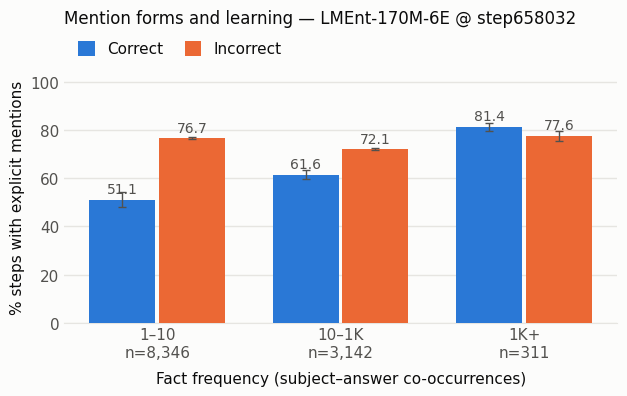

wrote /Users/private/Projects/Masters/NLP/NLPFinalProject/LMEnt_Research/work_170M_6E/fig9_170M.png


In [17]:
import matplotlib as mpl, matplotlib.pyplot as plt

INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"          # correct / incorrect
mpl.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF,
                     "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2,
                     "font.size": 11, "axes.grid": False})

d = out[out.pct_steps_explicit.notna() & (out.num_shared_chunks >= 1)].copy()
d["bucket"] = pd.cut(d.num_shared_chunks, [0, 10, 1000, np.inf],
                     labels=["1–10", "10–1K", "1K+"])

g = (d.groupby(["bucket", "correct"], observed=True)
       .pct_steps_explicit.agg(["mean", "sem", "size"]).reset_index())
tbl = g.pivot(index="bucket", columns="correct", values=["mean", "size"])
print(tbl.round(2).to_string(), "\n")

fig, ax = plt.subplots(figsize=(6.4, 4.1))
x, w = np.arange(3), 0.36
for k, (flag, color, lab) in enumerate([(True, BLUE, "Correct"), (False, ORANGE, "Incorrect")]):
    s = g[g.correct == flag].set_index("bucket").reindex(["1–10", "10–1K", "1K+"])
    pos = x + (k - 0.5) * (w + 0.02)          # 2px-equivalent gap between adjacent bars
    ax.bar(pos, s["mean"], w, yerr=s["sem"], color=color, label=lab,
           error_kw=dict(ecolor=INK2, lw=1, capsize=3), zorder=3)
    for xi, v, nn in zip(pos, s["mean"], s["size"]):
        if np.isfinite(v):
            ax.text(xi, v + 1.5, f"{v:.1f}", ha="center", va="bottom",
                    fontsize=10, color=INK2)

ax.set_xticks(x)
ax.set_xticklabels([f"{b}\nn={int(g[g.bucket==b]['size'].sum()):,}"
                    for b in ["1–10", "10–1K", "1K+"]])
ax.set_xlabel("Fact frequency (subject–answer co-occurrences)", labelpad=8)
ax.set_ylabel("% steps with explicit mentions")
ax.set_ylim(0, 105)
ax.yaxis.grid(True, color=GRID, lw=1, zorder=0)
ax.set_axisbelow(True)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(length=0)
ax.legend(frameon=False, loc="lower left", ncols=2, bbox_to_anchor=(0, 1.0),
          handlelength=1.1, handleheight=1.1, columnspacing=1.4)
ax.set_title(f"Mention forms and learning — {MODEL_ID.split('/')[-1]} @ {CKPT}",
             loc="left", pad=34, fontsize=12)
fig.tight_layout()
fig.savefig(f"{WORK}/fig9_170M.png", dpi=200, bbox_inches="tight")
plt.show()
print("wrote", f"{WORK}/fig9_170M.png")

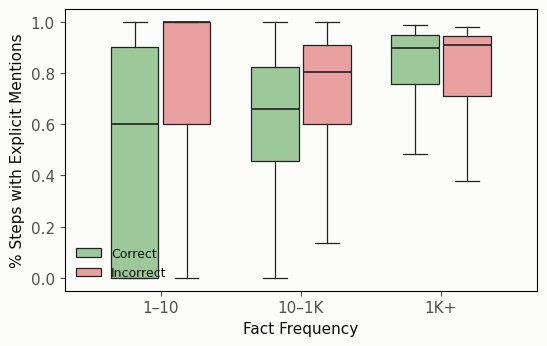

In [18]:
BUCKETS = ["1–10", "10–1K", "1K+"]
GREEN, RED = "#9dc99a", "#e8a0a0"

d = out[out.pct_steps_explicit.notna() & (out.num_shared_chunks >= 1)].copy()
d["bucket"] = pd.cut(d.num_shared_chunks, [0, 10, 1000, np.inf], labels=BUCKETS)
d["frac"]   = d.pct_steps_explicit / 100.0          # paper's y-axis is 0–1

fig, ax = plt.subplots(figsize=(5.6, 3.6))
x, w = np.arange(3), 0.34
for k, (flag, color, lab) in enumerate([(True, GREEN, "Correct"), (False, RED, "Incorrect")]):
    data = [d.loc[(d.bucket == b) & (d.correct == flag), "frac"].values for b in BUCKETS]
    bp = ax.boxplot(data, positions=x + (k - 0.5) * (w + 0.03), widths=w,
                    patch_artist=True, showfliers=False,
                    medianprops=dict(color="#222", lw=1.2),
                    boxprops=dict(facecolor=color, edgecolor="#222", lw=0.9),
                    whiskerprops=dict(color="#222", lw=0.9),
                    capprops=dict(color="#222", lw=0.9))
    bp["boxes"][0].set_label(lab)

ax.set_xticks(x); ax.set_xticklabels(BUCKETS)
ax.set_xlabel("Fact Frequency"); ax.set_ylabel("% Steps with Explicit Mentions")
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()


## Notes, and where this departs from the paper

**Faithful.** The chunk→document→mention resolution mirrors
`NumpyKASVSLDataset.__getitem__`; the 0.3 candidate threshold, `is_pronoun`, and
`normalize_span_text` are LMEnt's own; the eval mirrors `olmes` PopQA down to the
`is_safe` leak filter and the substring scoring.

**Judgement calls — change these if you disagree.**

1. **Canonical vs. alias.** The paper illustrates the split ("Donald Trump" vs.
   "the 47th president") without publishing a rule. We call a mention *explicit*
   when its normalised surface form equals a canonical name — `subj`/`s_wiki_title`
   from PopQA, or the candidate's own `name`. That is stricter than treating any
   entity-linked span as explicit: "Trump" alone lands in *alias*. Loosen it in
   `classify` (cell 9) if you want token-subset matching, and the absolute heights
   move even though the correct-vs-incorrect gap is robust to it.
2. **`MAX_STEPS_PER_FACT = N_EPOCHS * 1000`** touches only the 311 facts in the `1K+` bucket;
   `1–10` and `10–1K` are computed exactly. Because whole steps are sampled (never
   partial ones) the estimator is unbiased, not merely approximate — the per-fact
   standard error is ≤ `0.5/√6000` ≈ 0.6 pp, which averages down to well under
   0.1 pp on the bucket mean. Setting `0` removes sampling entirely at a higher
   parsing cost; worth doing for a published number, but it should not move the
   figure.
3. **Correctness is measured at `step658032` only.** The paper's grouping is
   final-checkpoint correctness; the learned/forgotten distinction needs no extra
   compute here — point cell 12c at the other 13 parquets in
   `170M_6E_15shot_trajectory/` (`step0` … `step600000`) and rerun the figure.
4. **Exposure is measured over epoch 6** (`EPOCHS = [6]`, global steps
   548,360–658,032) — the epoch running up to the checkpoint we score. Because
   every fact sees all of its chunks in every epoch, this ratio is close to
   epoch-invariant, so one epoch buys the full-run answer at 1/6 the cost. What is
   *not* interchangeable is **which** epoch: `batch_indices.npy` is byte-identical
   to `batch_indices_epoch_1.npy`, so the obvious default would have measured
   epoch 1 and paired it with end-of-epoch-6 correctness. Set
   `EPOCHS = list(range(1, 7))` to pool the whole run — see cell 6.
5. **This is the 170M model, not the 1B.** Its PopQA accuracy is far lower, so the
   `correct` group is smaller and noisier — the `sem` bars and the printed `size`
   column matter. A flat or reversed `1–10` bucket is the *expected* result (the
   paper finds all steps explicit there regardless of correctness); the signal to
   look for is the correct-vs-incorrect gap widening in `1K+`.
5. **Both-explicit is per chunk, not per sentence.** A VSL chunk can be up to 2048
   tokens, so "both mentioned explicitly in the same chunk" is a weaker
   co-occurrence claim than adjacency.